# Pemrosesan Data KBJI 2014 — test_v2

Notebook ini mengekstrak Jabatan enam digit dari Golongan Pokok 2 Profesional pada PDF KBJI 2014. Fokusnya adalah ketertelusuran hierarchy, audit nama, dan satu CSV lexical set gender untuk seluruh pipeline.

## 1. Import dan konfigurasi

Seluruh artefak baru memakai prefix test_v2_. Data test_v1 tidak disentuh.

In [1]:
import re
import sys
import unicodedata
from pathlib import Path

import numpy as np
import pandas as pd
import pdfplumber
import matplotlib.pyplot as plt
import seaborn as sns
from IPython.display import display

RANDOM_SEED = 42
rng = np.random.default_rng(RANDOM_SEED)
ROOT = Path.cwd()
DATA_DIR = ROOT / "data"
PDF_PATH = DATA_DIR / "KBJI 2014.pdf"
FULL_OUTPUT = DATA_DIR / "test_v2_kbji_profesional_all.csv"
ANALYSIS_OUTPUT = DATA_DIR / "test_v2_kbji_profesional_analysis.csv"
GENDER_OUTPUT = DATA_DIR / "test_v2_istilah_gender.csv"
assert PDF_PATH.exists()
print("Python:", sys.version.split()[0], "| PDF bytes:", PDF_PATH.stat().st_size)

Python: 3.13.15 | PDF bytes: 34550550


## 2. Lexical set gender sebagai satu sumber

Delapan pasangan ini adalah baseline operasional, bukan lexical set yang sudah tervalidasi final. Notebook pipeline membaca CSV yang ditulis di sini dan tidak mendefinisikan pasangan sendiri.

In [2]:
gender_rows = [
    (1, "laki-laki", "perempuan", "identitas umum", "netral", "operasional; validasi linguistik lanjutan diperlukan", True, "Baseline operasional."),
    (2, "pria", "wanita", "identitas umum", "netral", "operasional; validasi linguistik lanjutan diperlukan", True, "Register perlu ditinjau."),
    (3, "ayah", "ibu", "kekerabatan", "netral", "operasional; validasi linguistik lanjutan diperlukan", True, "Konteks kekerabatan tambahan."),
    (4, "suami", "istri", "perkawinan", "netral", "operasional; validasi linguistik lanjutan diperlukan", True, "Konteks relasional tambahan."),
    (5, "putra", "putri", "kekerabatan", "netral", "operasional; validasi linguistik lanjutan diperlukan", True, "Konteks kekerabatan/generasi."),
    (6, "pemuda", "pemudi", "usia/generasi", "netral", "operasional; validasi linguistik lanjutan diperlukan", True, "Perlu perhatian pada sensitivitas."),
    (7, "cowok", "cewek", "identitas umum", "informal", "operasional; validasi linguistik lanjutan diperlukan", True, "Register informal."),
    (8, "jejaka", "gadis", "usia/status", "netral", "operasional; validasi linguistik lanjutan diperlukan", True, "Perlu perhatian pada sensitivitas."),
]
gender_frame = pd.DataFrame(gender_rows, columns=["pair_id", "male_term", "female_term", "lexical_category", "register", "validation_status", "include_baseline", "notes"])
gender_frame.to_csv(GENDER_OUTPUT, index=False, encoding="utf-8")
gender_frame = pd.read_csv(GENDER_OUTPUT)
display(gender_frame)
display(gender_frame.groupby(["lexical_category", "register"]).size().rename("pair_count").reset_index())
assert len(gender_frame) == 8 and gender_frame.pair_id.is_unique
assert gender_frame.male_term.is_unique and gender_frame.female_term.is_unique

,pair_id,male_term,female_term,lexical_category,register,validation_status,include_baseline,notes
0,1,laki-laki,perempuan,identitas umum,netral,operasional; validasi linguistik lanjutan dipe...,True,Baseline operasional.
1,2,pria,wanita,identitas umum,netral,operasional; validasi linguistik lanjutan dipe...,True,Register perlu ditinjau.
2,3,ayah,ibu,kekerabatan,netral,operasional; validasi linguistik lanjutan dipe...,True,Konteks kekerabatan tambahan.
3,4,suami,istri,perkawinan,netral,operasional; validasi linguistik lanjutan dipe...,True,Konteks relasional tambahan.
4,5,putra,putri,kekerabatan,netral,operasional; validasi linguistik lanjutan dipe...,True,Konteks kekerabatan/generasi.
5,6,pemuda,pemudi,usia/generasi,netral,operasional; validasi linguistik lanjutan dipe...,True,Perlu perhatian pada sensitivitas.
6,7,cowok,cewek,identitas umum,informal,operasional; validasi linguistik lanjutan dipe...,True,Register informal.
7,8,jejaka,gadis,usia/status,netral,operasional; validasi linguistik lanjutan dipe...,True,Perlu perhatian pada sensitivitas.


,lexical_category,register,pair_count
0,identitas umum,informal,1
1,identitas umum,netral,2
2,kekerabatan,netral,2
3,perkawinan,netral,1
4,usia/generasi,netral,1
5,usia/status,netral,1


## 3. Ekstraksi hierarchy dari PDF

Scope ditentukan dari heading Golongan Pokok 2 PROFESIONAL sampai sebelum Golongan Pokok 3. Mapping parent dilakukan berdasarkan prefix kode.

In [3]:
def compact(value):
    return re.sub(r"\s+", " ", str(value)).strip()

with pdfplumber.open(PDF_PATH) as pdf:
    page_texts = [page.extract_text() or "" for page in pdf.pages]
start_page = next(i + 1 for i, text in enumerate(page_texts) if re.search(r"(?m)^Golongan Pokok$\s*\n^2\s+PROFESIONAL\s*$", text, re.I))
stop_page = start_page + next(i for i, text in enumerate(page_texts[start_page:], start=1) if re.search(r"(?m)^Golongan Pokok 3\s*$", text, re.I)) - 1
print({"start_page_pdf": start_page, "last_page_in_scope": stop_page})

p2, p3, p4, p6 = (re.compile(pattern) for pattern in [r"^(\d{2})\s+(.+)$", r"^(\d{3})\s+(.+)$", r"^(\d{4})\s+(.+)$", r"^(\d{4}\.\d{2})\s+(.+)$"])
major_groups, groups, subgroups, occupations = {}, {}, {}, []
marker = None
for page_number in range(start_page, stop_page + 1):
    page_text = page_texts[page_number - 1]
    for raw_line in page_text.splitlines():
        line = compact(raw_line)
        if line in {"Golongan", "Subgolongan", "Jabatan"}:
            marker = line
            continue
        match = p6.match(line)
        if marker == "Jabatan" and match:
            occupation_code, name = match.groups()
            printed = re.search(r"Halaman\s+(\d+)", page_text)
            occupations.append({"occupation_code": occupation_code, "occupation_name_raw": name, "source_page_pdf": page_number, "source_page_printed": printed.group(1) if printed else pd.NA})
            continue
        match = p4.match(line)
        if marker == "Subgolongan" and match:
            subgroups.setdefault(*match.groups())
            continue
        match = p3.match(line)
        if marker == "Golongan" and match:
            groups.setdefault(*match.groups())
            continue
        match = p2.match(line)
        if match and match.group(1) in {"21", "22", "23", "24", "25", "26"}:
            major_groups.setdefault(*match.groups())
print("Jabatan:", len(occupations), "| Subgolongan Pokok:", len(major_groups), "| Golongan:", len(groups), "| Subgolongan:", len(subgroups))

{'start_page_pdf': 159, 'last_page_in_scope': 330}
Jabatan: 501 | Subgolongan Pokok: 6 | Golongan: 27 | Subgolongan: 92


## 4. Normalisasi konservatif dan audit nama Jabatan

occupation_name_raw dipertahankan. Representasi tanpa parenthetical hanya pembanding sensitivitas; tidak ada stemming atau stopword removal agresif.

In [4]:
FOREIGN_MARKERS = {"assistant", "coach", "computer", "designer", "engineer", "hotel", "marketing", "network", "operator", "quality", "software", "tourism", "web"}

def normalize_name(value, without_parenthetical=False):
    text = unicodedata.normalize("NFKC", compact(value)).lower()
    if without_parenthetical:
        text = re.sub(r"\([^)]*\)", " ", text)
    text = re.sub(r"\(\s*umum\s*\)", " ", text).replace("/", " ")
    return compact(re.sub(r"[^\w\s-]", " ", text, flags=re.UNICODE))

def audit_name(value):
    raw = unicodedata.normalize("NFKC", compact(value))
    has_parenthetical = bool(re.search(r"\([^)]*\)", raw))
    contains_slash = "/" in raw
    tokens = re.findall(r"[a-z0-9]+(?:-[a-z0-9]+)*", raw.lower())
    has_foreign = bool(set(tokens) & FOREIGN_MARKERS)
    notes = []
    if has_parenthetical: notes.append("teks dalam tanda kurung")
    if has_foreign: notes.append("indikator istilah asing/Inggris")
    if contains_slash: notes.append("memuat slash")
    return {"occupation_text": normalize_name(raw), "occupation_text_without_parenthetical": normalize_name(raw, True), "has_parenthetical_text": has_parenthetical, "has_english_or_foreign_term": has_foreign, "contains_slash": contains_slash, "representation_notes": "; ".join(notes) if notes else "tidak ada penanda khusus"}

df_all = pd.DataFrame(occupations)
df_all["major_group_code"], df_all["major_group_name"] = "2", "Profesional"
df_all["submajor_group_code"] = df_all.occupation_code.str[:2]
df_all["submajor_group_name"] = df_all.submajor_group_code.map(major_groups)
df_all["group_code"] = df_all.occupation_code.str[:3]
df_all["group_name"] = df_all.group_code.map(groups)
df_all["subgroup_code"] = df_all.occupation_code.str[:4]
df_all["subgroup_name"] = df_all.subgroup_code.map(subgroups)
df_all = pd.concat([df_all, pd.DataFrame(df_all.occupation_name_raw.map(audit_name).tolist())], axis=1)
df_all["token_count"] = df_all.occupation_text.str.split().str.len()
gender_terms = set(gender_frame.male_term) | set(gender_frame.female_term)
df_all["is_valid_code"] = df_all.occupation_code.str.fullmatch(r"\d{4}\.\d{2}") & df_all.submajor_group_code.isin(major_groups)
df_all["is_duplicate"] = df_all.occupation_code.duplicated(keep=False)
df_all["is_residual"] = df_all.occupation_code.str.endswith(".99") | df_all.occupation_name_raw.str.contains(r"lainnya|ybdi|ytdl", case=False, na=False)
df_all["contains_gender_attribute"] = df_all.occupation_text.map(lambda x: bool(set(x.split()) & gender_terms))
df_all["hierarchy_complete"] = df_all[["submajor_group_name", "group_name", "subgroup_name"]].notna().all(axis=1)
df_all["hierarchy_prefix_match"] = df_all.submajor_group_code.isin(major_groups) & df_all.group_code.isin(groups) & df_all.subgroup_code.isin(subgroups)
df_all["code_name_conflict"] = df_all.groupby("occupation_code").occupation_name_raw.transform("nunique").gt(1)
df_all["duplicate_occupation_text"] = df_all.occupation_text.duplicated(keep=False)
df_all["name_nonempty"] = df_all.occupation_text.ne("")
df_all["include_analysis"] = df_all.is_valid_code & ~df_all.is_duplicate & ~df_all.is_residual & ~df_all.contains_gender_attribute & df_all.hierarchy_complete & df_all.hierarchy_prefix_match & ~df_all.code_name_conflict & df_all.name_nonempty

def exclusion_reason(row):
    reasons = []
    if not row.is_valid_code: reasons.append("kode tidak valid")
    if row.is_duplicate: reasons.append("kode duplikat")
    if row.is_residual: reasons.append("kategori residual")
    if row.contains_gender_attribute: reasons.append("lexical leakage atribut gender")
    if not row.hierarchy_complete or not row.hierarchy_prefix_match: reasons.append("hierarki tidak lengkap")
    if row.code_name_conflict: reasons.append("konflik kode-nama")
    if row.duplicate_occupation_text: reasons.append("teks Jabatan duplikat")
    if not row.name_nonempty: reasons.append("nama kosong")
    return "; ".join(reasons)

df_all["exclusion_reason"] = df_all.apply(exclusion_reason, axis=1)
df_analysis = df_all[df_all.include_analysis].copy()
display(df_all.head(10))
display(df_all[["occupation_name_raw", "occupation_text", "occupation_text_without_parenthetical", "representation_notes"]].head(15))
display(df_all.dtypes.rename("dtype").to_frame())
display(df_all.isna().sum().rename("missing_count").to_frame())

,occupation_code,occupation_name_raw,source_page_pdf,source_page_printed,major_group_code,major_group_name,submajor_group_code,submajor_group_name,group_code,group_name,...,is_duplicate,is_residual,contains_gender_attribute,hierarchy_complete,hierarchy_prefix_match,code_name_conflict,duplicate_occupation_text,name_nonempty,include_analysis,exclusion_reason
0,2111.01,Ahli Fisika (Umum),161,121,2,Profesional,21,Ahli ilmu pengetahuan dan teknik,211,Ahli Fisika dan Ilmu Bumi,...,False,False,False,True,True,False,False,True,True,
1,2111.02,Ahli Fisika Nuklir,161,121,2,Profesional,21,Ahli ilmu pengetahuan dan teknik,211,Ahli Fisika dan Ilmu Bumi,...,False,False,False,True,True,False,False,True,True,
2,2111.03,Ahli Fisika Mekanika,161,121,2,Profesional,21,Ahli ilmu pengetahuan dan teknik,211,Ahli Fisika dan Ilmu Bumi,...,False,False,False,True,True,False,False,True,True,
3,2111.04,Ahli Fisika Panas,161,121,2,Profesional,21,Ahli ilmu pengetahuan dan teknik,211,Ahli Fisika dan Ilmu Bumi,...,False,False,False,True,True,False,False,True,True,
4,2111.05,Ahli Fisika Sinar,162,122,2,Profesional,21,Ahli ilmu pengetahuan dan teknik,211,Ahli Fisika dan Ilmu Bumi,...,False,False,False,True,True,False,False,True,True,
5,2111.06,Ahli Fisika Suara,162,122,2,Profesional,21,Ahli ilmu pengetahuan dan teknik,211,Ahli Fisika dan Ilmu Bumi,...,False,False,False,True,True,False,False,True,True,
6,2111.07,Ahli Fisika Listrik Dan Magnit,162,122,2,Profesional,21,Ahli ilmu pengetahuan dan teknik,211,Ahli Fisika dan Ilmu Bumi,...,False,False,False,True,True,False,False,True,True,
7,2111.08,Ahli Fisika Elektronika,162,122,2,Profesional,21,Ahli ilmu pengetahuan dan teknik,211,Ahli Fisika dan Ilmu Bumi,...,False,False,False,True,True,False,False,True,True,
8,2111.09,Ahli Fisika Medis,163,123,2,Profesional,21,Ahli ilmu pengetahuan dan teknik,211,Ahli Fisika dan Ilmu Bumi,...,False,False,False,True,True,False,False,True,True,
9,2111.10,Ahli Astronomi,163,123,2,Profesional,21,Ahli ilmu pengetahuan dan teknik,211,Ahli Fisika dan Ilmu Bumi,...,False,False,False,True,True,False,False,True,True,


,occupation_name_raw,occupation_text,occupation_text_without_parenthetical,representation_notes
0,Ahli Fisika (Umum),ahli fisika,ahli fisika,teks dalam tanda kurung
1,Ahli Fisika Nuklir,ahli fisika nuklir,ahli fisika nuklir,tidak ada penanda khusus
2,Ahli Fisika Mekanika,ahli fisika mekanika,ahli fisika mekanika,tidak ada penanda khusus
3,Ahli Fisika Panas,ahli fisika panas,ahli fisika panas,tidak ada penanda khusus
4,Ahli Fisika Sinar,ahli fisika sinar,ahli fisika sinar,tidak ada penanda khusus
5,Ahli Fisika Suara,ahli fisika suara,ahli fisika suara,tidak ada penanda khusus
6,Ahli Fisika Listrik Dan Magnit,ahli fisika listrik dan magnit,ahli fisika listrik dan magnit,tidak ada penanda khusus
7,Ahli Fisika Elektronika,ahli fisika elektronika,ahli fisika elektronika,tidak ada penanda khusus
8,Ahli Fisika Medis,ahli fisika medis,ahli fisika medis,tidak ada penanda khusus
9,Ahli Astronomi,ahli astronomi,ahli astronomi,tidak ada penanda khusus


,dtype
occupation_code,str
occupation_name_raw,str
source_page_pdf,int64
source_page_printed,str
major_group_code,str
major_group_name,str
submajor_group_code,str
submajor_group_name,str
group_code,str
group_name,str


,missing_count
occupation_code,0
occupation_name_raw,0
source_page_pdf,0
source_page_printed,0
major_group_code,0
major_group_name,0
submajor_group_code,0
submajor_group_name,0
group_code,0
group_name,0


## 5. Quality control pemrosesan dan fokus kelompok

,level,unique_code_count
0,Golongan Pokok,1
1,Subgolongan Pokok,6
2,Golongan,27
3,Subgolongan,92
4,Jabatan,501


,metric,value
0,baris mentah,501
1,baris analisis,415
2,residual,85
3,lexical leakage,1
4,duplikasi kode,0
5,konflik kode-nama,0
6,teks Jabatan duplikat,0
7,hierarki tidak lengkap,0
8,teks parenthetical,44
9,indikator asing/slash,13


,submajor_group_code,submajor_group_name,occupation_count,analysis_count
0,21,Ahli ilmu pengetahuan dan teknik,161,138
1,22,Profesional kesehatan,89,74
2,23,Profesional pendidikan,52,42
3,24,Profesional bisnis dan administrasi,38,29
4,25,Profesional teknologi informasi dan komunikasi,34,26
5,26,"Profesional hukum, sosial dan budaya",127,106


,group_code,group_name,occupation_count
0,211,Ahli Fisika dan Ilmu Bumi,28
1,212,"Ahli Matematika, Aktuaria Dan Statistika",8
2,213,Ahli Ilmu Pengetahuan Hayati,28
3,214,Ahli Teknik (Selain Ahli Teknologi Elektro),52
4,215,Ahli Teknik Teknologi Elektro,13
5,216,"Arsitek, Perencana, Surveyor dan Desainer",32
6,221,Dokter Medis,22
7,222,Profesional Keperawatan dan Kebidanan,9
8,223,Profesional Pengobatan Tradisional dan Komplem...,7
9,224,Praktisi Paramedis,4


,occupation_code,occupation_name_raw,exclusion_reason
10,2111.99,Ahli Fisika dan Astronomi Lainnya,kategori residual
15,2112.99,Ahli Meteorologi dan Klimatologi Lainnya,kategori residual
21,2113.99,Ahli Kimia Lainnya,kategori residual
27,2114.99,Ahli Geologi Dan Geofisika Lainnya,kategori residual
35,2120.99,"Ahli Matematika, Aktuaria Dan Statistika Lainnya",kategori residual
49,2131.99,"Ahli Biologi, Botani, Zoologi dan YBDI Lainnya",kategori residual
55,2132.99,"Penasihat Pertanian, Kehutanan dan Perikanan L...",kategori residual
63,2133.99,Ahli Perlindungan Lingkungan Lainnya,kategori residual
69,2141.99,Ahli Teknik Industri dan Produksi Lainnya,kategori residual
79,2142.99,Ahli Teknik Sipil Lainnya,kategori residual


,occupation_code,occupation_name_raw,exclusion_reason
422,2635.09,Organisator Kesejahteraan Perempuan,lexical leakage atribut gender


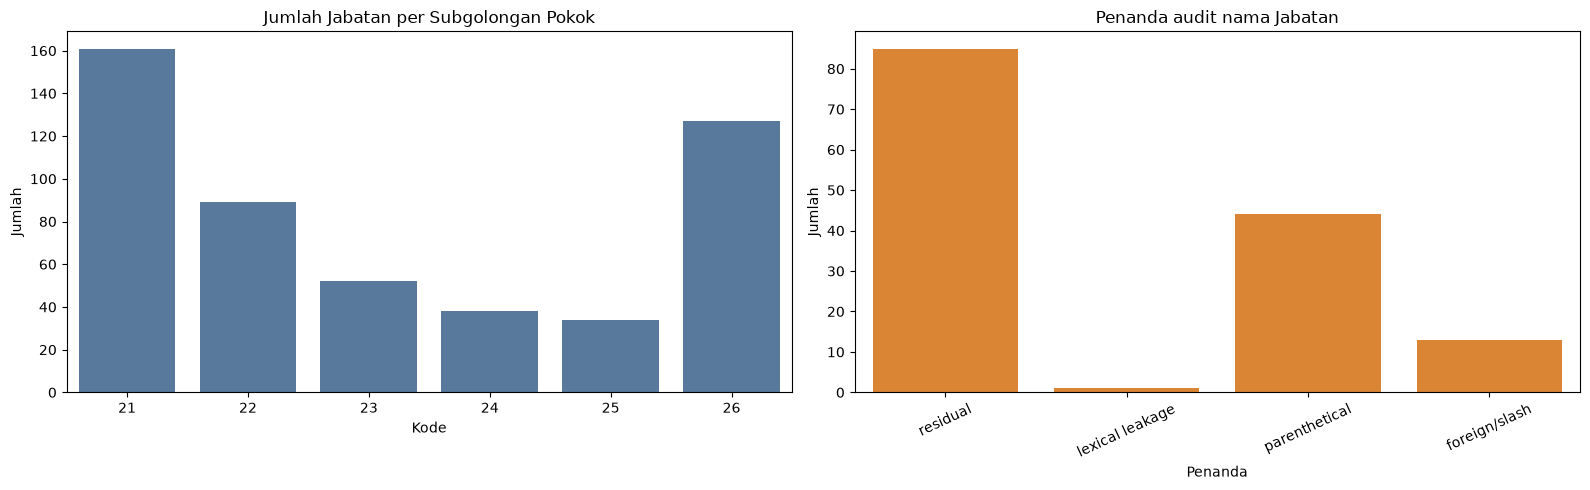

In [5]:
hierarchy_counts = pd.DataFrame({"level": ["Golongan Pokok", "Subgolongan Pokok", "Golongan", "Subgolongan", "Jabatan"], "unique_code_count": [df_all.major_group_code.nunique(), df_all.submajor_group_code.nunique(), df_all.group_code.nunique(), df_all.subgroup_code.nunique(), df_all.occupation_code.nunique()]})
audit_processing = pd.DataFrame({"metric": ["baris mentah", "baris analisis", "residual", "lexical leakage", "duplikasi kode", "konflik kode-nama", "teks Jabatan duplikat", "hierarki tidak lengkap", "teks parenthetical", "indikator asing/slash"], "value": [len(df_all), len(df_analysis), int(df_all.is_residual.sum()), int(df_all.contains_gender_attribute.sum()), int(df_all.is_duplicate.sum()), int(df_all.code_name_conflict.sum()), int(df_all.duplicate_occupation_text.sum()), int((~df_all.hierarchy_complete).sum()), int(df_all.has_parenthetical_text.sum()), int((df_all.has_english_or_foreign_term | df_all.contains_slash).sum())]})
display(hierarchy_counts); display(audit_processing)
display(df_all.groupby(["submajor_group_code", "submajor_group_name"], dropna=False).agg(occupation_count=("occupation_code", "count"), analysis_count=("include_analysis", "sum")).reset_index())
display(df_all.groupby(["group_code", "group_name"], dropna=False).size().rename("occupation_count").reset_index())
display(df_all[df_all.is_residual][["occupation_code", "occupation_name_raw", "exclusion_reason"]].head(10))
display(df_all[df_all.contains_gender_attribute][["occupation_code", "occupation_name_raw", "exclusion_reason"]])
fig, axes = plt.subplots(1, 2, figsize=(16, 5))
counts = df_all.groupby(["submajor_group_code", "submajor_group_name"]).size().reset_index(name="occupation_count")
sns.barplot(data=counts, x="submajor_group_code", y="occupation_count", color="#4C78A8", ax=axes[0])
flags = pd.DataFrame({"audit": ["residual", "lexical leakage", "parenthetical", "foreign/slash"], "count": [df_all.is_residual.sum(), df_all.contains_gender_attribute.sum(), df_all.has_parenthetical_text.sum(), (df_all.has_english_or_foreign_term | df_all.contains_slash).sum()]})
sns.barplot(data=flags, x="audit", y="count", color="#F58518", ax=axes[1]); axes[1].tick_params(axis="x", rotation=25)
axes[0].set(title="Jumlah Jabatan per Subgolongan Pokok", xlabel="Kode", ylabel="Jumlah")
axes[1].set(title="Penanda audit nama Jabatan", xlabel="Penanda", ylabel="Jumlah")
plt.tight_layout(); plt.show()

## 6. Menulis, membaca kembali, dan validasi

In [6]:
df_all.to_csv(FULL_OUTPUT, index=False, encoding="utf-8")
df_analysis.to_csv(ANALYSIS_OUTPUT, index=False, encoding="utf-8")
readback_dtype = {"occupation_code": str, "major_group_code": str, "submajor_group_code": str, "group_code": str, "subgroup_code": str, "source_page_printed": str}
full_reload = pd.read_csv(FULL_OUTPUT, dtype=readback_dtype)
analysis_reload = pd.read_csv(ANALYSIS_OUTPUT, dtype=readback_dtype)
gender_reload = pd.read_csv(GENDER_OUTPUT)
for frame in (df_all, full_reload, df_analysis, analysis_reload):
    frame["source_page_printed"] = frame["source_page_printed"].fillna("")
    frame["exclusion_reason"] = frame["exclusion_reason"].fillna("")
pd.testing.assert_frame_equal(df_all.reset_index(drop=True), full_reload.reset_index(drop=True), check_dtype=False)
pd.testing.assert_frame_equal(df_analysis.reset_index(drop=True), analysis_reload.reset_index(drop=True), check_dtype=False)
pd.testing.assert_frame_equal(gender_frame.reset_index(drop=True), gender_reload.reset_index(drop=True), check_dtype=False)
display(full_reload.head()); display(analysis_reload.head())
checkpoint_rows = [("501 Jabatan mentah", 501, len(df_all)), ("6 Subgolongan Pokok", 6, df_all.submajor_group_code.nunique()), ("27 Golongan", 27, df_all.group_code.nunique()), ("92 Subgolongan", 92, df_all.subgroup_code.nunique()), ("85 kategori residual", 85, int(df_all.is_residual.sum())), ("1 lexical leakage", 1, int(df_all.contains_gender_attribute.sum())), ("415 Jabatan analisis", 415, len(df_analysis))]
validation_processing = pd.DataFrame([{"check_name": name, "expected": expected, "observed": observed, "status": "PASS" if expected == observed else "FAIL", "notes": "checkpoint hasil ekstraksi aktual"} for name, expected, observed in checkpoint_rows] + [{"check_name": "hierarchy lengkap dan prefix match", "expected": True, "observed": bool(df_all.hierarchy_complete.all() and df_all.hierarchy_prefix_match.all()), "status": "PASS" if bool(df_all.hierarchy_complete.all() and df_all.hierarchy_prefix_match.all()) else "FAIL", "notes": "mapping parent berdasarkan prefix"}, {"check_name": "kode Jabatan unik", "expected": True, "observed": bool(df_all.occupation_code.is_unique), "status": "PASS" if bool(df_all.occupation_code.is_unique) else "FAIL", "notes": "duplikasi eksplisit"}, {"check_name": "CSV konsisten setelah read-back", "expected": True, "observed": True, "status": "PASS", "notes": "frame equality"}])
display(validation_processing)
assert (validation_processing.status == "PASS").all()

,occupation_code,occupation_name_raw,source_page_pdf,source_page_printed,major_group_code,major_group_name,submajor_group_code,submajor_group_name,group_code,group_name,...,is_duplicate,is_residual,contains_gender_attribute,hierarchy_complete,hierarchy_prefix_match,code_name_conflict,duplicate_occupation_text,name_nonempty,include_analysis,exclusion_reason
0,2111.01,Ahli Fisika (Umum),161,121,2,Profesional,21,Ahli ilmu pengetahuan dan teknik,211,Ahli Fisika dan Ilmu Bumi,...,False,False,False,True,True,False,False,True,True,
1,2111.02,Ahli Fisika Nuklir,161,121,2,Profesional,21,Ahli ilmu pengetahuan dan teknik,211,Ahli Fisika dan Ilmu Bumi,...,False,False,False,True,True,False,False,True,True,
2,2111.03,Ahli Fisika Mekanika,161,121,2,Profesional,21,Ahli ilmu pengetahuan dan teknik,211,Ahli Fisika dan Ilmu Bumi,...,False,False,False,True,True,False,False,True,True,
3,2111.04,Ahli Fisika Panas,161,121,2,Profesional,21,Ahli ilmu pengetahuan dan teknik,211,Ahli Fisika dan Ilmu Bumi,...,False,False,False,True,True,False,False,True,True,
4,2111.05,Ahli Fisika Sinar,162,122,2,Profesional,21,Ahli ilmu pengetahuan dan teknik,211,Ahli Fisika dan Ilmu Bumi,...,False,False,False,True,True,False,False,True,True,


,occupation_code,occupation_name_raw,source_page_pdf,source_page_printed,major_group_code,major_group_name,submajor_group_code,submajor_group_name,group_code,group_name,...,is_duplicate,is_residual,contains_gender_attribute,hierarchy_complete,hierarchy_prefix_match,code_name_conflict,duplicate_occupation_text,name_nonempty,include_analysis,exclusion_reason
0,2111.01,Ahli Fisika (Umum),161,121,2,Profesional,21,Ahli ilmu pengetahuan dan teknik,211,Ahli Fisika dan Ilmu Bumi,...,False,False,False,True,True,False,False,True,True,
1,2111.02,Ahli Fisika Nuklir,161,121,2,Profesional,21,Ahli ilmu pengetahuan dan teknik,211,Ahli Fisika dan Ilmu Bumi,...,False,False,False,True,True,False,False,True,True,
2,2111.03,Ahli Fisika Mekanika,161,121,2,Profesional,21,Ahli ilmu pengetahuan dan teknik,211,Ahli Fisika dan Ilmu Bumi,...,False,False,False,True,True,False,False,True,True,
3,2111.04,Ahli Fisika Panas,161,121,2,Profesional,21,Ahli ilmu pengetahuan dan teknik,211,Ahli Fisika dan Ilmu Bumi,...,False,False,False,True,True,False,False,True,True,
4,2111.05,Ahli Fisika Sinar,162,122,2,Profesional,21,Ahli ilmu pengetahuan dan teknik,211,Ahli Fisika dan Ilmu Bumi,...,False,False,False,True,True,False,False,True,True,


,check_name,expected,observed,status,notes
0,501 Jabatan mentah,501,501,PASS,checkpoint hasil ekstraksi aktual
1,6 Subgolongan Pokok,6,6,PASS,checkpoint hasil ekstraksi aktual
2,27 Golongan,27,27,PASS,checkpoint hasil ekstraksi aktual
3,92 Subgolongan,92,92,PASS,checkpoint hasil ekstraksi aktual
4,85 kategori residual,85,85,PASS,checkpoint hasil ekstraksi aktual
5,1 lexical leakage,1,1,PASS,checkpoint hasil ekstraksi aktual
6,415 Jabatan analisis,415,415,PASS,checkpoint hasil ekstraksi aktual
7,hierarchy lengkap dan prefix match,True,True,PASS,mapping parent berdasarkan prefix
8,kode Jabatan unik,True,True,PASS,duplikasi eksplisit
9,CSV konsisten setelah read-back,True,True,PASS,frame equality
